# Import

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Graph question 1

In [2]:
# 1) which item do customers put in their cart first

# on va prendre tt les items, on va faire une moyenne de leurs position dans le cart, et on va ensuite afficher pour chaque item ca position 
# dans le cart dans l'ordre croissant

CSV_untouch = pd.read_csv('CSV_Cleaned.csv')

# on fait ici un groupby pour permettre de regroupper touts nos achats de produits sous les meme produits et de permettre d'avoir leurs moyenne d'emplacement dans le panier d'un client
CSV_Clean = CSV_untouch.groupby(
    ["product_name"]
).agg(
    {
        "add_to_cart_order": "mean"   
    }
)

# on retirer les index
CSV_Clean = CSV_Clean.reset_index()





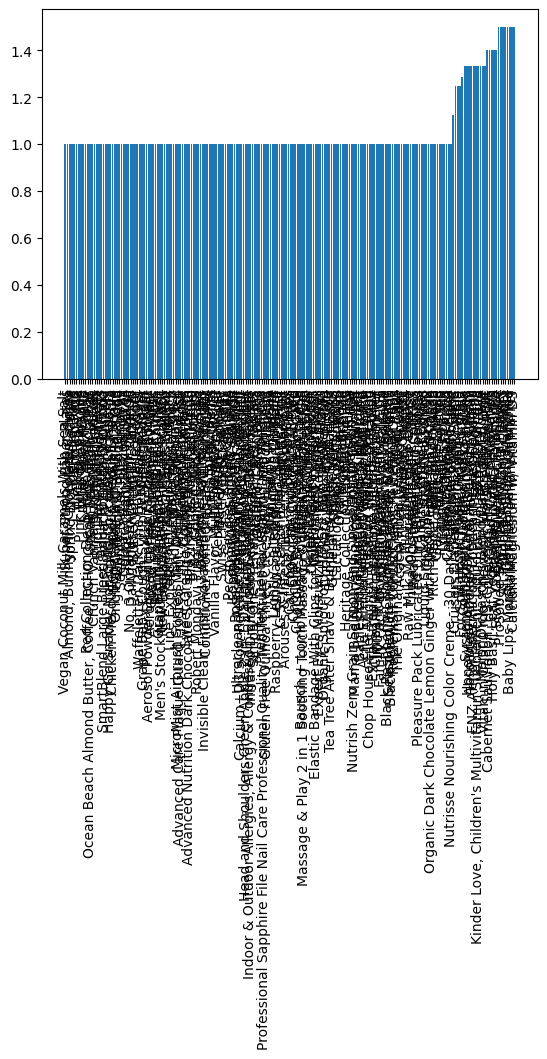

In [3]:
CSV_Clean = CSV_Clean.sort_values(by=["add_to_cart_order"])
DF = CSV_Clean.head(200)
# print(DF)
x = DF['product_name']
y = DF['add_to_cart_order']
plt.bar(x,y)
plt.tick_params(axis='x', labelrotation=90)

plt.show()

# Graph question 5

197233


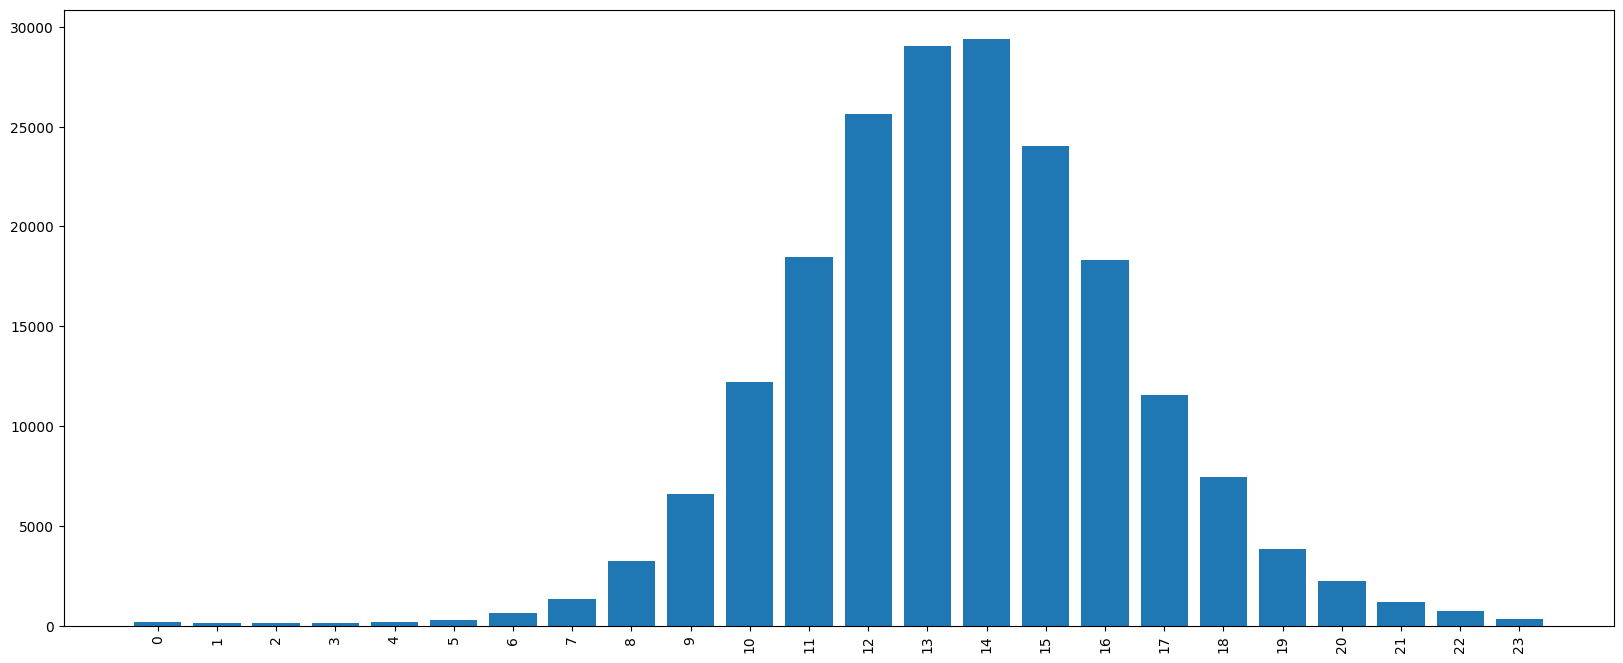

In [12]:
#Quel est l'horaire ou il y a le plus d'achat de nourriture


# on va prendre suppriner les items qui ne sont pas de la nourriture.
CSV_untouch = pd.read_csv('CSV_Cleaned.csv')

# on defini les departement qui ne sont pas des aliments
Bad_DEPARTEMENT = ['other', 'pets', 'personal care', 'house hold']
CSV_untouch = CSV_untouch.drop(CSV_untouch[CSV_untouch.department.isin(Bad_DEPARTEMENT)].index)


CSV_Clean = CSV_untouch.groupby(
    ["user_id"]
).agg(
    {
        "order_hour_of_day": "mean"
    }
)
DF = round(CSV_Clean, 0)
# print(len(DF))
listeheure = {}

for k in DF["order_hour_of_day"]:
    if k not in listeheure:
        listeheure[k] = 1
    else:
        listeheure[k] += 1

x = listeheure.keys()
y = listeheure.values()
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)
ax = plt.gca()
ax.set_xticks(range(0, 24, 1))

plt.show()